In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

print("Libraries loaded")

Libraries loaded


In [2]:
results_aggregate = pd.read_csv("results_aggregate.csv")
results_aggregate.shape

(150, 25)

### Predictions and probabilites analysis

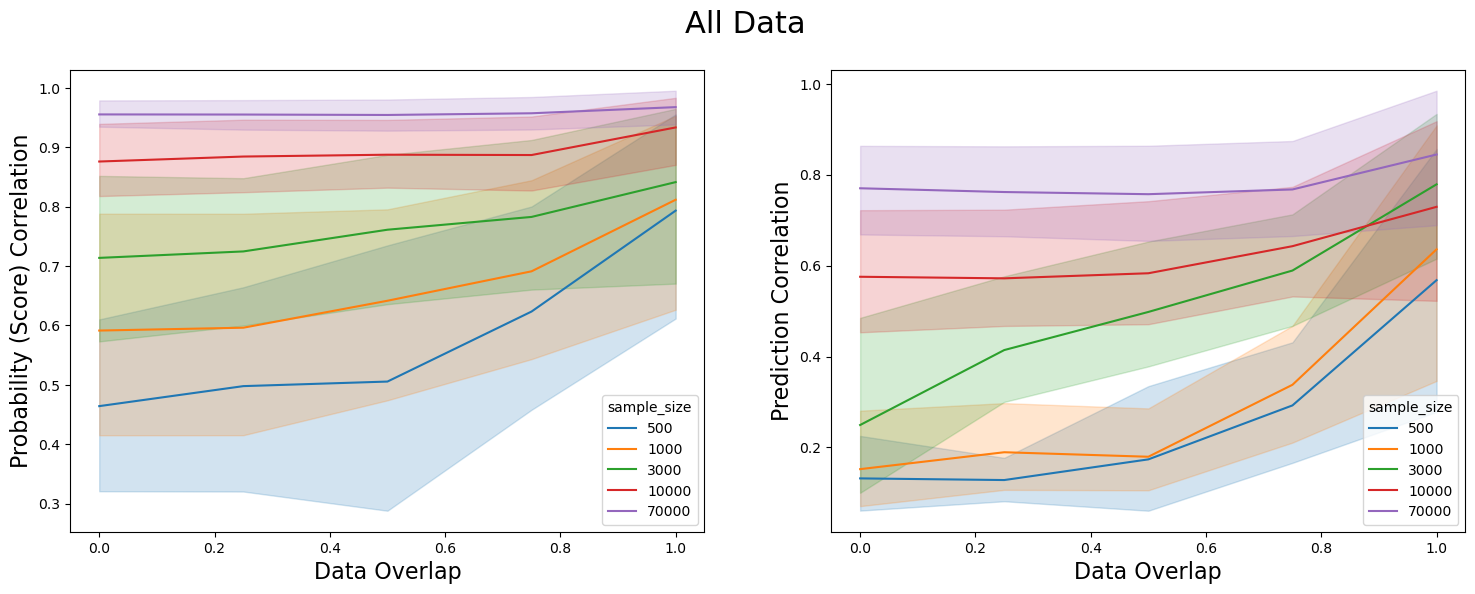

In [3]:
fig , ax = plt.subplots(1, 2 , figsize=(18,6))

fig.suptitle("All Data", fontsize=22)


sns.lineplot(
    data=results_aggregate,
    x="data_overlap",
    y="prob_corr",
    hue="sample_size",
    palette="tab10" ,
    ax = ax[0]
)
ax[0].set_xlabel("Data Overlap", fontsize=16)
ax[0].set_ylabel("Probability (Score) Correlation", fontsize=16)



sns.lineplot(
    data=results_aggregate,
    x="data_overlap",
    y="pred_corr",
    hue="sample_size",
    palette="tab10" ,
    ax = ax[1]
)
ax[1].set_xlabel("Data Overlap", fontsize=16)
ax[1].set_ylabel("Prediction Correlation", fontsize=16)

plt.show()

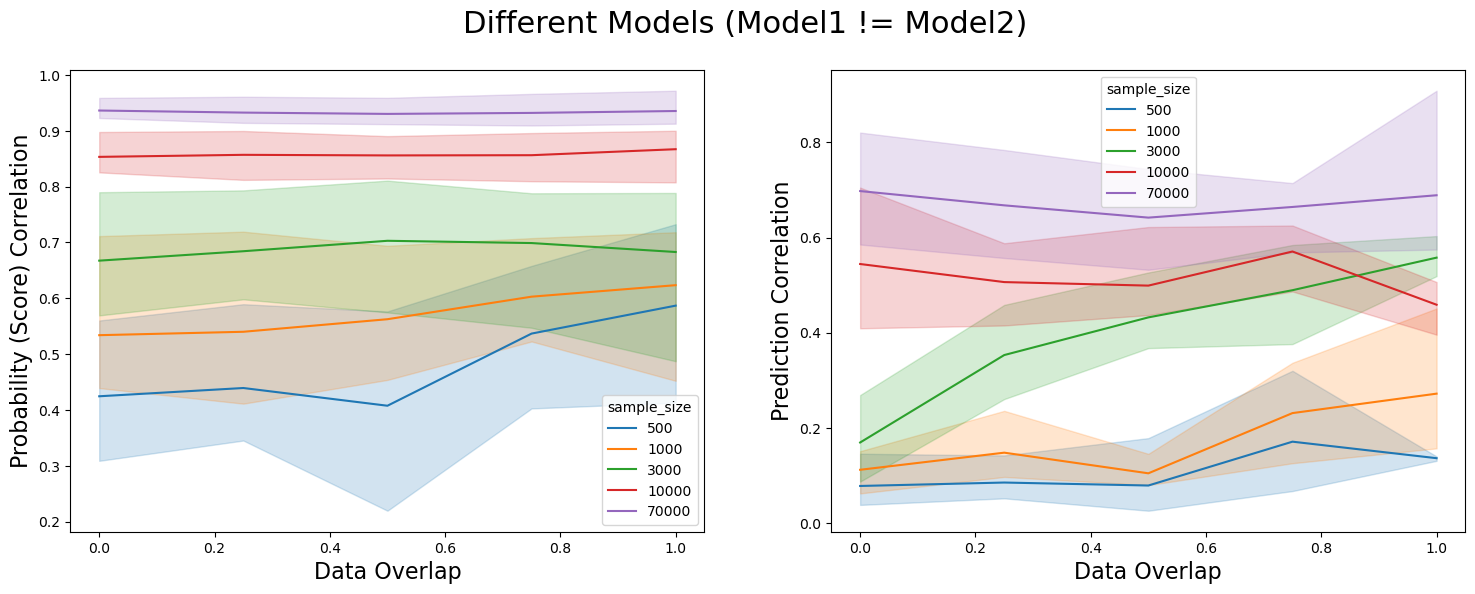

In [4]:
fig , ax = plt.subplots(1, 2 , figsize=(18,6))

fig.suptitle("Different Models (Model1 != Model2)", fontsize=22)


sns.lineplot(
    data=results_aggregate[results_aggregate['model1'] != results_aggregate['model2']],
    x="data_overlap",
    y="prob_corr",
    hue="sample_size",
    palette="tab10" ,
    ax = ax[0]
)
ax[0].set_xlabel("Data Overlap", fontsize=16)
ax[0].set_ylabel("Probability (Score) Correlation", fontsize=16)



sns.lineplot(
    data=results_aggregate[results_aggregate['model1'] != results_aggregate['model2']],
    x="data_overlap",
    y="pred_corr",
    hue="sample_size",
    palette="tab10" ,
    ax = ax[1]
)
ax[1].set_xlabel("Data Overlap", fontsize=16)
ax[1].set_ylabel("Prediction Correlation", fontsize=16)


plt.show()

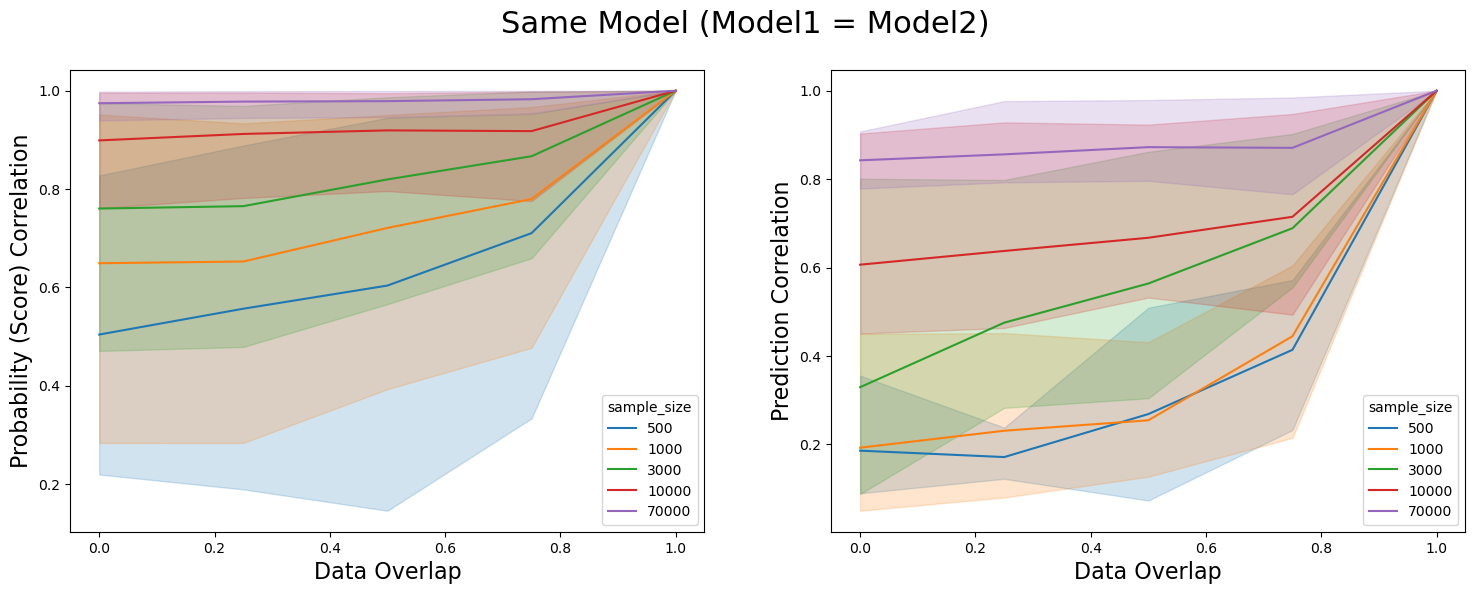

In [5]:
fig , ax = plt.subplots(1, 2 , figsize=(18,6))

fig.suptitle("Same Model (Model1 = Model2)", fontsize=22)


sns.lineplot(
    data=results_aggregate[results_aggregate['model1'] == results_aggregate['model2']],
    x="data_overlap",
    y="prob_corr",
    hue="sample_size",
    palette="tab10" ,
    ax = ax[0]
)
ax[0].set_xlabel("Data Overlap", fontsize=16)
ax[0].set_ylabel("Probability (Score) Correlation", fontsize=16)



sns.lineplot(
    data=results_aggregate[results_aggregate['model1'] == results_aggregate['model2']],
    x="data_overlap",
    y="pred_corr",
    hue="sample_size",
    palette="tab10" ,
    ax = ax[1]
)
ax[1].set_xlabel("Data Overlap", fontsize=16)
ax[1].set_ylabel("Prediction Correlation", fontsize=16)


plt.show()

### FN analysis

In [6]:
results_aggregate["model_pair"] = np.where(
    results_aggregate["model1"] == results_aggregate["model2"],
    "Same model",
    "Different models"
)

lift_FN_mean = results_aggregate["FN_lift"].mean()
excess_FN_mean = results_aggregate["FN_excess"].mean()

print("Overall:")
print("Lift FN mean:", lift_FN_mean)
print("Excess FN mean:", excess_FN_mean)

FN_summary = (
    results_aggregate
    .groupby("model_pair")[["FN_lift", "FN_excess"]]
    .mean()
)

print("\nBy model pair:")
print(FN_summary)

Overall:
Lift FN mean: 20.263797835015467
Excess FN mean: 0.016024414492497255

By model pair:
                    FN_lift  FN_excess
model_pair                            
Different models  13.543699   0.011418
Same model        26.983897   0.020630


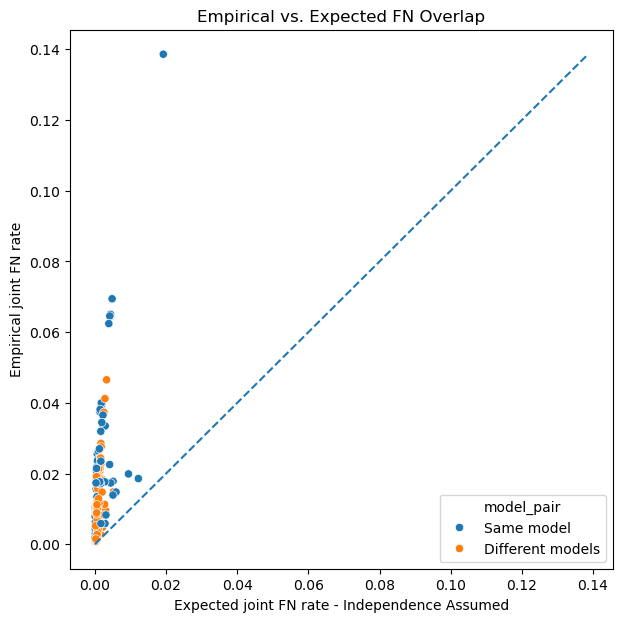

In [7]:
plt.figure(figsize=(7, 7))

sns.scatterplot(
    data=results_aggregate,
    x="expected_FN_both",
    y="empirical_FN_both",
    hue="model_pair"
)

line_max = max(
    results_aggregate["expected_FN_both"].max(),
    results_aggregate["empirical_FN_both"].max()
)

plt.plot([0, line_max], [0, line_max], "--")

plt.xlabel("Expected joint FN rate - Independence Assumed")
plt.ylabel("Empirical joint FN rate")
plt.title("Empirical vs. Expected FN Overlap")

plt.show()

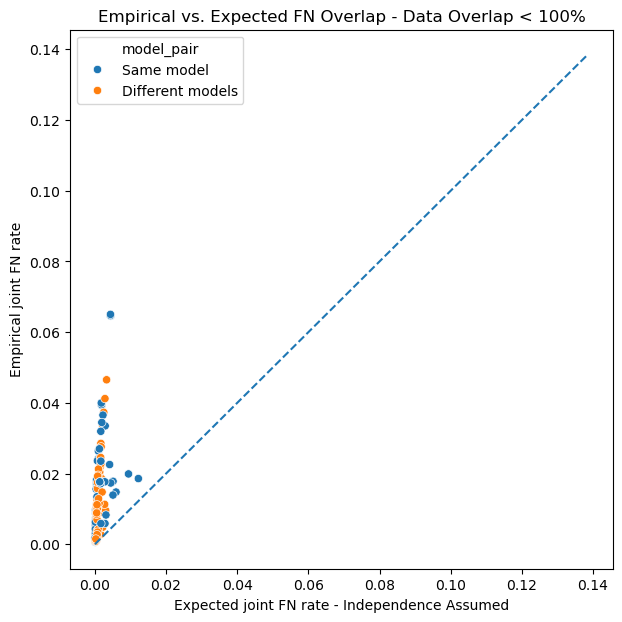

In [8]:
plt.figure(figsize=(7, 7))

sns.scatterplot(
    data=results_aggregate[results_aggregate['data_overlap'] < 1],
    x="expected_FN_both",
    y="empirical_FN_both",
    hue="model_pair"
)

line_max = max(
    results_aggregate["expected_FN_both"].max(),
    results_aggregate["empirical_FN_both"].max()
)

plt.plot([0, line_max], [0, line_max], "--")

plt.xlabel("Expected joint FN rate - Independence Assumed")
plt.ylabel("Empirical joint FN rate")
plt.title("Empirical vs. Expected FN Overlap - Data Overlap < 100%")

plt.show()

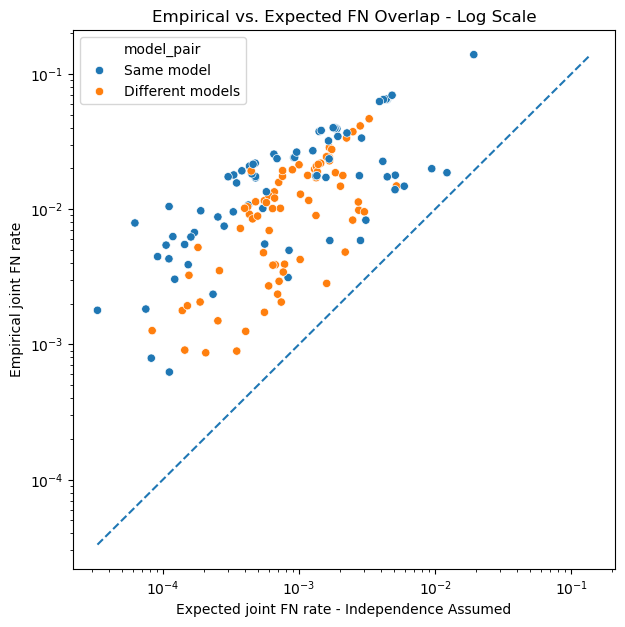

In [18]:
plt.figure(figsize=(7, 7))

sns.scatterplot(
    data=results_aggregate,
    x="expected_FN_both",
    y="empirical_FN_both",
    hue="model_pair"
)

plt.xscale("log")
plt.yscale("log")

line_min = min(
    results_aggregate.loc[results_aggregate["expected_FN_both"] > 0, "expected_FN_both"].min(),
    results_aggregate.loc[results_aggregate["empirical_FN_both"] > 0, "empirical_FN_both"].min()
)

line_max = max(
    results_aggregate["expected_FN_both"].max(),
    results_aggregate["empirical_FN_both"].max()
)

plt.plot(
    [line_min, line_max],
    [line_min, line_max],
    "--"
)

plt.xlabel("Expected joint FN rate - Independence Assumed")
plt.ylabel("Empirical joint FN rate")
plt.title("Empirical vs. Expected FN Overlap - Log Scale")

plt.show()

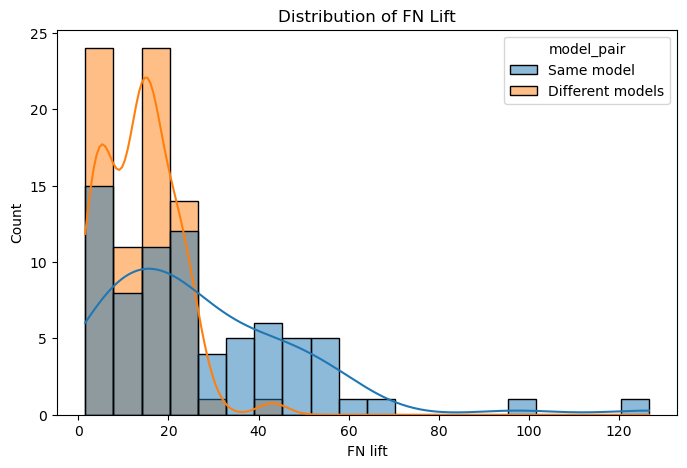

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=results_aggregate,
    x="FN_lift",
    hue="model_pair",
    bins=20,
    kde=True
)

plt.xlabel("FN lift")
plt.title("Distribution of FN Lift")

plt.show()

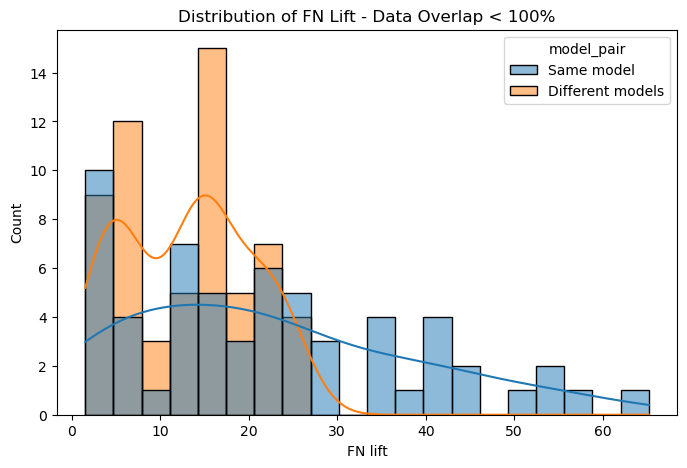

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=results_aggregate[results_aggregate['data_overlap'] < 1],
    x="FN_lift",
    hue="model_pair",
    bins=20,
    kde=True
)

plt.xlabel("FN lift")
plt.title("Distribution of FN Lift - Data Overlap < 100%")

plt.show()

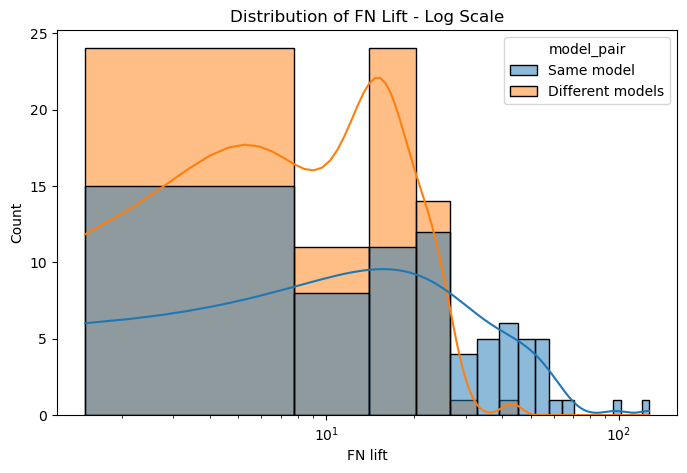

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=results_aggregate,
    x="FN_lift",
    hue="model_pair",
    bins=20,
    kde=True
)

plt.xscale("log")

plt.xlabel("FN lift")
plt.title("Distribution of FN Lift - Log Scale")

plt.show()

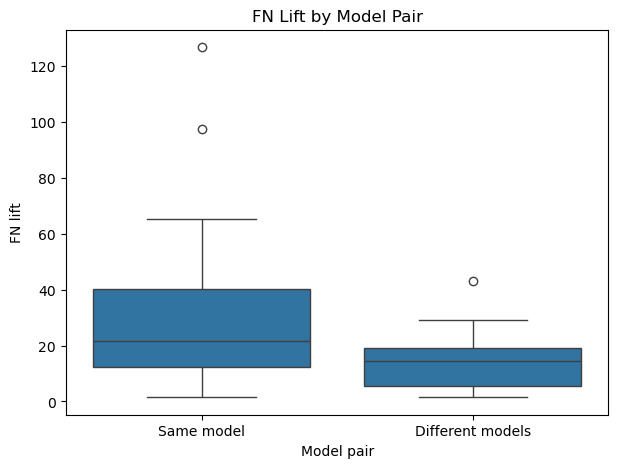

In [11]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=results_aggregate,
    x="model_pair",
    y="FN_lift"
)

plt.xlabel("Model pair")
plt.ylabel("FN lift")
plt.title("FN Lift by Model Pair")

plt.show()

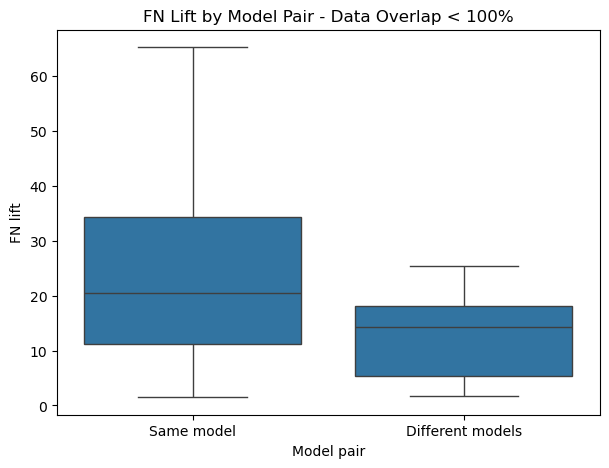

In [12]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=results_aggregate[results_aggregate['data_overlap'] < 1],
    x="model_pair",
    y="FN_lift"
)

plt.xlabel("Model pair")
plt.ylabel("FN lift")
plt.title("FN Lift by Model Pair - Data Overlap < 100%")

plt.show()

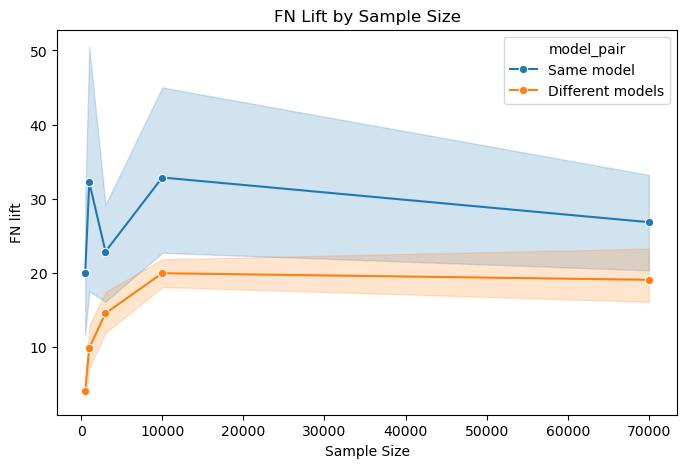

In [13]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=results_aggregate,
    x="sample_size",
    y="FN_lift",
    hue="model_pair",
    marker="o"
)

plt.xlabel("Sample Size")
plt.ylabel("FN lift")
plt.title("FN Lift by Sample Size")

plt.show()

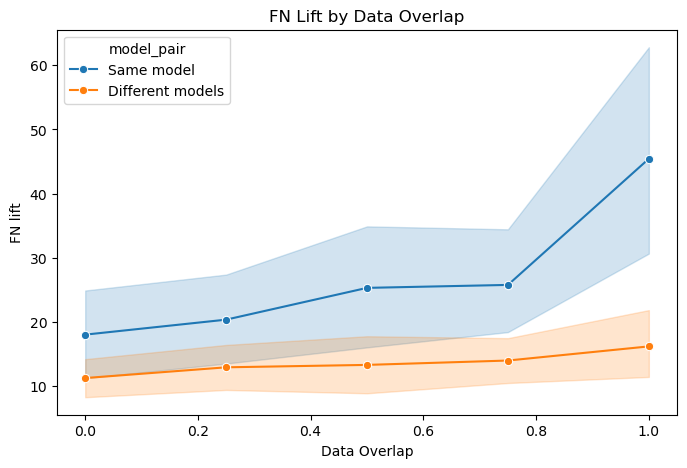

In [14]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=results_aggregate,
    x="data_overlap",
    y="FN_lift",
    hue="model_pair",
    marker="o"
)

plt.xlabel("Data Overlap")
plt.ylabel("FN lift")
plt.title("FN Lift by Data Overlap")


plt.show()